In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

In [20]:
path =  '/glade/derecho/scratch/sakor/bulk/era5_init/graphcast/graphcast_20220204_00z_168h.nc'

In [21]:
ds = xr.open_dataset(
    path,
    decode_timedelta=False
)


In [22]:
import re
import xarray as xr


class AINWPPreprocessor:
    """
    Preprocess AI-NWP datasets by:

    1. Subsetting the CONUS domain
    2. Converting longitude to -180 to 180 if needed
    3. Renaming lat/lon -> latitude/longitude
    4. Stacking pressure-level variables into a 'level' dimension
    5. Leaving surface-only variables unchanged
    6. Adding standardized units and variable metadata

    Pressure levels are ordered from surface to top of atmosphere:
    high pressure -> low pressure.
    """

    def __init__(
        self,
        pressure_vars=("t", "z", "u", "v", "w", "q"),
        lat_bounds=(24.0, 50.0),
        lon_bounds=(-125.0, -66.0),
    ):
        self.pressure_vars = pressure_vars
        self.lat_bounds = lat_bounds
        self.lon_bounds = lon_bounds

        # --------------------------------------------------
        # Standard variable metadata
        # --------------------------------------------------
        self.variable_metadata = {

            # Pressure-level variables
            "t": {
                "long_name": "air temperature",
                "units": "K",
            },
            "z": {
                "long_name": "geopotential",
                "units": "m2 s-2",
            },
            "u": {
                "long_name": "eastward wind",
                "units": "m s-1",
            },
            "v": {
                "long_name": "northward wind",
                "units": "m s-1",
            },
            "w": {
                "long_name": "pressure vertical velocity",
                "units": "Pa s-1",
            },
            "q": {
                "long_name": "specific humidity",
                "units": "kg kg-1",
            },

            # Surface variables
            "t2m": {
                "long_name": "2 metre temperature",
                "units": "K",
            },
            "u10m": {
                "long_name": "10 metre eastward wind",
                "units": "m s-1",
            },
            "v10m": {
                "long_name": "10 metre northward wind",
                "units": "m s-1",
            },
            "msl": {
                "long_name": "mean sea level pressure",
                "units": "Pa",
            },
            "tp06": {
                "long_name": "6-hour accumulated total precipitation",
                "units": "m",
                "accumulation_period": "6 hours",
            },
        }

    def subset_conus(self, ds):
        """
        Subset dataset to the CONUS domain.

        Handles either:
            longitude = 0 ... 360
        or
            longitude = -180 ... 180
        """

        lat_name = (
            "lat"
            if "lat" in ds.coords
            else "latitude"
        )

        lon_name = (
            "lon"
            if "lon" in ds.coords
            else "longitude"
        )

        lat_min, lat_max = self.lat_bounds
        lon_min, lon_max = self.lon_bounds

        # --------------------------------------------------
        # Convert longitude to -180 ... 180
        # --------------------------------------------------
        if ds[lon_name].max() > 180:
            ds = ds.assign_coords(
                {
                    lon_name: (
                        (ds[lon_name] + 180) % 360
                    ) - 180
                }
            )

            ds = ds.sortby(lon_name)

        # --------------------------------------------------
        # Make latitude increasing
        # --------------------------------------------------
        if ds[lat_name][0] > ds[lat_name][-1]:
            ds = ds.sortby(lat_name)

        # --------------------------------------------------
        # Subset CONUS
        # --------------------------------------------------
        ds = ds.sel(
            {
                lat_name: slice(
                    lat_min,
                    lat_max,
                ),
                lon_name: slice(
                    lon_min,
                    lon_max,
                ),
            }
        )

        return ds

    def get_levels(self, ds, var):
        """
        Infer pressure levels for a variable.

        Example
        -------
        t1000, t925, t850, ..., t50

        Returns
        -------
        [1000, 925, 850, ..., 50]
        """

        pattern = re.compile(
            rf"^{re.escape(var)}(\d+)$"
        )

        levels = [
            int(match.group(1))
            for name in ds.data_vars
            if (match := pattern.match(name))
        ]

        return sorted(
            levels,
            reverse=True,
        )

    def stack_levels(self, ds, var):
        """
        Stack level-specific variables into one level dimension.

        Example
        -------
        t1000, t925, ..., t50

        becomes

        t(
            time,
            lead_time,
            level,
            latitude,
            longitude
        )
        """

        levels = self.get_levels(
            ds,
            var,
        )

        if not levels:
            raise ValueError(
                f"No pressure levels found for '{var}'"
            )

        arrays = [
            ds[f"{var}{level}"]
            .expand_dims(level=[level])
            for level in levels
        ]

        da = xr.concat(
            arrays,
            dim="level",
        )

        # --------------------------------------------------
        # Pressure coordinate metadata
        # --------------------------------------------------
        da["level"].attrs = {
            "long_name": "pressure level",
            "standard_name": "air_pressure",
            "units": "hPa",
            "positive": "down",
            "axis": "Z",
        }

        return da

    def rename_spatial_dims(self, ds):
        """
        Rename:
            lat -> latitude
            lon -> longitude
        """

        rename_dict = {}

        if (
            "lat" in ds.dims
            or "lat" in ds.coords
        ):
            rename_dict["lat"] = "latitude"

        if (
            "lon" in ds.dims
            or "lon" in ds.coords
        ):
            rename_dict["lon"] = "longitude"

        if rename_dict:
            ds = ds.rename(rename_dict)

        return ds

    def add_metadata(self, ds):
        """
        Add standardized units and descriptive metadata
        to atmospheric and surface variables.
        """

        # --------------------------------------------------
        # Data variables
        # --------------------------------------------------
        for var, attrs in self.variable_metadata.items():

            if var not in ds.data_vars:
                continue

            ds[var].attrs.update(
                attrs
            )

        # --------------------------------------------------
        # Latitude
        # --------------------------------------------------
        if "latitude" in ds.coords:
            ds["latitude"].attrs.update(
                {
                    "standard_name": "latitude",
                    "long_name": "latitude",
                    "units": "degrees_north",
                    "axis": "Y",
                }
            )

        # --------------------------------------------------
        # Longitude
        # --------------------------------------------------
        if "longitude" in ds.coords:
            ds["longitude"].attrs.update(
                {
                    "standard_name": "longitude",
                    "long_name": "longitude",
                    "units": "degrees_east",
                    "axis": "X",
                }
            )

        # --------------------------------------------------
        # Pressure level
        # --------------------------------------------------
        if "level" in ds.coords:
            ds["level"].attrs.update(
                {
                    "standard_name": "air_pressure",
                    "long_name": "pressure level",
                    "units": "hPa",
                    "positive": "down",
                    "axis": "Z",
                }
            )

        # --------------------------------------------------
        # Lead time
        # --------------------------------------------------
        if "lead_time" in ds.coords:
            ds["lead_time"].attrs.update(
                {
                    "long_name": "forecast lead time",
                }
            )

        return ds

    def process(self, ds):
        """
        Run complete preprocessing pipeline.
        """

        # --------------------------------------------------
        # 1. Subset CONUS
        # --------------------------------------------------
        ds = self.subset_conus(
            ds
        )

        # --------------------------------------------------
        # 2. Standardize spatial coordinate names
        # --------------------------------------------------
        ds = self.rename_spatial_dims(
            ds
        )

        out = ds.copy()

        # --------------------------------------------------
        # 3. Stack pressure-level variables
        # --------------------------------------------------
        for var in self.pressure_vars:

            levels = self.get_levels(
                ds,
                var,
            )

            if not levels:
                continue

            stacked = self.stack_levels(
                ds,
                var,
            )

            stacked = stacked.transpose(
                "time",
                "lead_time",
                "level",
                "latitude",
                "longitude",
            )

            out[var] = stacked

            # Remove:
            # t1000, t925, t850, ...
            level_vars = [
                f"{var}{level}"
                for level in levels
            ]

            out = out.drop_vars(
                level_vars
            )

        # --------------------------------------------------
        # 4. Add standardized metadata
        # --------------------------------------------------
        out = self.add_metadata(
            out
        )

        return out

In [23]:
processor = AINWPPreprocessor()

ds_processed = processor.process(ds)

# ds_processed

In [24]:
import xarray as xr
import numpy as np
import metpy.calc as mpcalc
from metpy.units import units
from numba import njit, prange

In [25]:
# ================================================================
# MACHINE-LEARNING PRECIPITATION-TYPE CLASSIFICATION
# ================================================================

from keras.models import load_model

from mlguess.keras.models import CategoricalDNN
from mlguess.keras.losses import evidential_cat_loss

from bridgescaler.backend import load_scaler

import numpy as np
import pandas as pd
import xarray as xr

In [26]:
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr

import metpy.calc as mpcalc
from metpy.units import units

from numba import njit, prange

from keras.models import load_model

from mlguess.keras.models import CategoricalDNN
from mlguess.keras.losses import evidential_cat_loss

from bridgescaler.backend import load_scaler


# ================================================================
# CONSTANTS
# ================================================================

PTYPE_CLASSES = [
    "rain",
    "snow",
    "ice pellets",
    "freezing rain",
]

PTYPE_SHORT_NAMES = [
    "rain",
    "snow",
    "icep",
    "frzr",
]

# IMPORTANT:
# This is the feature-block ordering used to construct
# the 84-element atmospheric profile.
PROFILE_VARS = [
    "T_HEIGHT",
    "DPT_HEIGHT",
    "U_HEIGHT",
    "V_HEIGHT",
]

EXPECTED_HEIGHTS = np.arange(
    0,
    5001,
    250,
    dtype=np.float32,
)

N_HEIGHTS = len(EXPECTED_HEIGHTS)
N_FEATURES = len(PROFILE_VARS) * N_HEIGHTS


# ================================================================
# LOAD MODEL + SCALER
# ================================================================

def load_saved_model(
    model_path: str,
    scaler_path: str,
):
    """
    Load the trained precipitation-type model and Bridgescaler.

    Returns
    -------
    model
    scaler
    input_features
        Exact feature names/order stored with the scaler.
    """

    custom_objects = {
        "CategoricalDNN": CategoricalDNN,
        "evidential_cat_loss": evidential_cat_loss,
    }

    model = load_model(
        model_path,
        custom_objects=custom_objects,
        compile=False,
    )

    scaler = load_scaler(
        scaler_path
    )

    groups = scaler.groups_

    input_features = [
        feature
        for group in groups
        for feature in group
    ]

    if len(input_features) != N_FEATURES:
        raise ValueError(
            f"Scaler expects {len(input_features)} features, "
            f"but this workflow expects {N_FEATURES}."
        )

    print(
        f"Loaded ptype model: {model_path}"
    )

    print(
        f"Loaded scaler: {scaler_path}"
    )

    print(
        f"Scaler features: {len(input_features)}"
    )

    return (
        model,
        scaler,
        input_features,
    )


# ================================================================
# DEWPOINT
# ================================================================

def dewpoint_dataset(
    ds: xr.Dataset,
) -> xr.Dataset:
    """
    Calculate dewpoint and Celsius temperature for one forecast lead.

    Expected dimensions
    -------------------
    time
    level
    latitude
    longitude

    Uses:
        q -> specific humidity

    or:
        r -> relative humidity
    """

    ds = ds.copy()

    if "t" not in ds:
        raise KeyError(
            "Dataset must contain pressure-level temperature 't'."
        )

    # ------------------------------------------------------------
    # Temperature in Celsius
    # ------------------------------------------------------------

    ds["t_c"] = (
        ds["t"] - 273.15
    ).astype(
        np.float32
    )

    ds["t_c"].attrs = {
        "long_name": "air temperature",
        "units": "degC",
    }

    # ------------------------------------------------------------
    # Allocate dewpoint array
    # ------------------------------------------------------------

    dpt_values = np.empty(
        ds["t"].shape,
        dtype=np.float32,
    )

    time_values = ds["time"].values

    # ------------------------------------------------------------
    # Process each time
    # ------------------------------------------------------------

    for t_idx in range(
        len(time_values)
    ):

        # ========================================================
        # Specific humidity
        # ========================================================

        if "q" in ds:

            pressure = (
                ds["level"].values
                * 100.0
            )

            pressure = np.broadcast_to(
                pressure[:, None, None],
                ds["q"]
                .isel(time=t_idx)
                .shape,
            )

            pressure = (
                pressure
                * units.pascal
            )

            q = (
                ds["q"]
                .isel(time=t_idx)
                .values
                * units.dimensionless
            )

            td = (
                mpcalc
                .dewpoint_from_specific_humidity(
                    pressure,
                    q,
                )
                .to("degC")
            )

        # ========================================================
        # Relative humidity
        # ========================================================

        elif "r" in ds:

            temperature = (
                ds["t"]
                .isel(time=t_idx)
                .values
                * units.kelvin
            )

            rh = (
                ds["r"]
                .isel(time=t_idx)
                .values
            )

            # Allow RH stored as either:
            #     75.0
            # or
            #     0.75
            if np.nanmax(rh) > 1.5:
                rh = rh / 100.0

            rh = np.clip(
                rh,
                1e-5,
                1.0,
            )

            rh = (
                rh
                * units.dimensionless
            )

            td = (
                mpcalc
                .dewpoint_from_relative_humidity(
                    temperature,
                    rh,
                )
                .to("degC")
            )

        else:

            raise KeyError(
                "Dataset must contain either "
                "'q' or 'r'."
            )

        dpt_values[
            t_idx,
            ...,
        ] = (
            td.magnitude
            .astype(np.float32)
        )

    # ------------------------------------------------------------
    # Attach to Dataset
    # ------------------------------------------------------------

    ds["dpt"] = xr.DataArray(
        dpt_values,
        dims=ds["t"].dims,
        coords=ds["t"].coords,
        attrs={
            "long_name":
                "dew point temperature",
            "units":
                "degC",
        },
    )

    return ds


# ================================================================
# SURFACE GEOPOTENTIAL
# ================================================================

def prepare_surface_geopotential(
    surface_geopotential: xr.DataArray,
    ds: xr.Dataset,
) -> xr.DataArray:
    """
    Align ERA5 invariant surface geopotential with the AI-NWP grid.
    """

    surf = surface_geopotential.copy()

    rename_dict = {}

    if (
        "lat" in surf.dims
        or "lat" in surf.coords
    ):
        rename_dict["lat"] = "latitude"

    if (
        "lon" in surf.dims
        or "lon" in surf.coords
    ):
        rename_dict["lon"] = "longitude"

    if rename_dict:
        surf = surf.rename(
            rename_dict
        )

    # ------------------------------------------------------------
    # Remove singleton time
    # ------------------------------------------------------------

    if (
        "time" in surf.dims
        and surf.sizes["time"] == 1
    ):
        surf = surf.isel(
            time=0,
            drop=True,
        )

    # ------------------------------------------------------------
    # Longitude 0-360 -> -180-180
    # ------------------------------------------------------------

    if surf["longitude"].max() > 180:

        surf = surf.assign_coords(
            longitude=(
                (
                    surf["longitude"]
                    + 180
                )
                % 360
            )
            - 180
        )

        surf = surf.sortby(
            "longitude"
        )

    # ------------------------------------------------------------
    # Increasing latitude
    # ------------------------------------------------------------

    if (
        surf["latitude"][0]
        > surf["latitude"][-1]
    ):

        surf = surf.sortby(
            "latitude"
        )

    # ------------------------------------------------------------
    # Match forecast grid
    # ------------------------------------------------------------

    surf = surf.sel(
        latitude=ds["latitude"],
        longitude=ds["longitude"],
    )

    return surf


# ================================================================
# HEIGHT ABOVE GROUND LEVEL
# ================================================================

def compute_agl(
    ds: xr.Dataset,
    surface_geopotential: xr.DataArray,
    z_var: str = "z",
    g: float = 9.80665,
) -> xr.DataArray:
    """
    Calculate pressure-level height above ground level.
    """

    if z_var not in ds:
        raise KeyError(
            f"Dataset does not contain '{z_var}'."
        )

    surface_geopotential = (
        prepare_surface_geopotential(
            surface_geopotential,
            ds,
        )
    )

    # ------------------------------------------------------------
    # Geopotential -> height
    # ------------------------------------------------------------

    z_geo = (
        ds[z_var]
        / g
    )

    z_surface = (
        surface_geopotential
        / g
    )

    # ------------------------------------------------------------
    # Add time dimension
    # ------------------------------------------------------------

    if "time" not in z_surface.dims:

        z_surface = (
            z_surface
            .expand_dims(
                time=ds["time"]
            )
        )

    # ------------------------------------------------------------
    # AGL
    # ------------------------------------------------------------

    z_agl = (
        z_geo
        - z_surface
    ).astype(
        np.float32
    )

    z_agl = z_agl.transpose(
        "time",
        "level",
        "latitude",
        "longitude",
    )

    z_agl.name = "height_agl"

    z_agl.attrs = {
        "long_name":
            "height above ground level",
        "units":
            "m",
        "positive":
            "up",
    }

    return z_agl


# ================================================================
# NUMBA VERTICAL INTERPOLATION
# ================================================================

@njit(
    parallel=True
)
def interp_to_heights_numba(
    var,
    z_agl,
    target_heights,
):
    """
    Interpolate:

        time × level × latitude × longitude

    to:

        time × height × latitude × longitude
    """

    time, level, lat, lon = (
        var.shape
    )

    n_heights = len(
        target_heights
    )

    out = np.full(
        (
            time,
            n_heights,
            lat,
            lon,
        ),
        np.nan,
        dtype=np.float32,
    )

    for t in prange(
        time
    ):

        for i in prange(
            lat
        ):

            for j in range(
                lon
            ):

                heights = (
                    z_agl[
                        t,
                        :,
                        i,
                        j,
                    ]
                )

                values = (
                    var[
                        t,
                        :,
                        i,
                        j,
                    ]
                )

                # ----------------------------------------------
                # Ensure increasing vertical height
                # ----------------------------------------------

                if (
                    heights[0]
                    > heights[-1]
                ):

                    heights = (
                        heights[::-1]
                    )

                    values = (
                        values[::-1]
                    )

                # ----------------------------------------------
                # Preserve original interpolation behavior
                # ----------------------------------------------

                out[
                    t,
                    :,
                    i,
                    j,
                ] = np.interp(
                    target_heights,
                    heights,
                    values,
                )

    return out


# ================================================================
# INTERPOLATE PROFILE VARIABLES
# ================================================================

def interpolate_to_heights(
    ds: xr.Dataset,
    z_agl: xr.DataArray,
    target_heights: np.ndarray,
    vars_to_interp: list[str],
) -> xr.Dataset:
    """
    Interpolate selected atmospheric variables to fixed AGL heights.
    """

    target_heights = np.asarray(
        target_heights,
        dtype=np.float32,
    )

    z_values = (
        z_agl
        .transpose(
            "time",
            "level",
            "latitude",
            "longitude",
        )
        .values
        .astype(np.float32)
    )

    interpolated = {}

    for var_name in vars_to_interp:

        da = (
            ds[var_name]
            .transpose(
                "time",
                "level",
                "latitude",
                "longitude",
            )
        )

        values = (
            da.values
            .astype(np.float32)
        )

        output = (
            interp_to_heights_numba(
                values,
                z_values,
                target_heights,
            )
        )

        interpolated[
            var_name
        ] = xr.DataArray(
            output,
            dims=(
                "time",
                "height",
                "latitude",
                "longitude",
            ),
            coords={
                "time":
                    ds["time"],
                "height":
                    target_heights,
                "latitude":
                    ds["latitude"],
                "longitude":
                    ds["longitude"],
            },
            attrs=da.attrs,
        )

    result = xr.Dataset(
        interpolated
    )

    result["height"].attrs = {
        "long_name":
            "height above ground level",
        "units":
            "m",
        "positive":
            "up",
    }

    return result


# ================================================================
# EXTRACT 84 EDNN FEATURES
# ================================================================

def extract_variable_levels(
    dataset: xr.Dataset,
) -> np.ndarray:
    """
    Convert:

        T_HEIGHT
        DPT_HEIGHT
        U_HEIGHT
        V_HEIGHT

    at 21 heights into:

        (latitude * longitude, 84)

    Exact order:

        T[0:5000]
        Td[0:5000]
        U[0:5000]
        V[0:5000]
    """

    missing = [
        var
        for var in PROFILE_VARS
        if var not in dataset
    ]

    if missing:
        raise KeyError(
            "Missing profile variables: "
            + ", ".join(missing)
        )

    # ------------------------------------------------------------
    # Guarantee vertical ordering
    # ------------------------------------------------------------

    dataset = dataset.sortby(
        "height"
    )

    heights = (
        dataset["height"]
        .values
        .astype(np.float32)
    )

    if (
        len(heights)
        != N_HEIGHTS
    ):
        raise ValueError(
            f"Expected {N_HEIGHTS} heights; "
            f"found {len(heights)}."
        )

    if not np.allclose(
        heights,
        EXPECTED_HEIGHTS,
    ):
        raise ValueError(
            "Height coordinate does not match "
            "0-5000 m at 250-m increments."
        )

    lat_size = dataset.sizes[
        "latitude"
    ]

    lon_size = dataset.sizes[
        "longitude"
    ]

    data_array = np.empty(
        (
            N_FEATURES,
            lat_size,
            lon_size,
        ),
        dtype=np.float32,
    )

    k = 0

    # ------------------------------------------------------------
    # Explicit order:
    #
    # T -> Td -> U -> V
    # ------------------------------------------------------------

    for var_name in PROFILE_VARS:

        values = (
            dataset[var_name]
            .isel(time=0)
            .transpose(
                "height",
                "latitude",
                "longitude",
            )
            .values
        )

        data_array[
            k:k + N_HEIGHTS,
            ...,
        ] = values

        k += N_HEIGHTS

    # ------------------------------------------------------------
    # [84, lat, lon]
    #
    # -> [lat * lon, 84]
    # ------------------------------------------------------------

    return (
        data_array
        .reshape(
            N_FEATURES,
            -1,
        )
        .T
    )


# ================================================================
# SCALE MODEL INPUT
# ================================================================

def transform_data(
    input_data: np.ndarray,
    transformer,
    input_features,
):
    """
    Apply the exact scaler used during EDNN training.
    """

    if (
        input_data.shape[1]
        != len(input_features)
    ):
        raise ValueError(
            f"Input contains "
            f"{input_data.shape[1]} features, "
            f"but scaler expects "
            f"{len(input_features)}."
        )

    input_df = pd.DataFrame(
        input_data,
        columns=input_features,
    )

    return transformer.transform(
        input_df
    )


# ================================================================
# TENSOR -> NUMPY
# ================================================================

def to_numpy(
    value,
) -> np.ndarray:

    if isinstance(
        value,
        np.ndarray,
    ):
        return value

    if hasattr(
        value,
        "detach",
    ):
        value = value.detach()

    if hasattr(
        value,
        "cpu",
    ):
        value = value.cpu()

    if hasattr(
        value,
        "numpy",
    ):
        value = value.numpy()

    return np.asarray(
        value
    )


# ================================================================
# EDNN INFERENCE
# ================================================================

def run_model_prediction(
    model,
    input_data,
):
    """
    Run the precipitation-type EDNN.
    """

    if hasattr(
        model,
        "predict",
    ):

        return model.predict(
            input_data,
            verbose=0,
        )

    return model(
        input_data,
        training=False,
    )


# ================================================================
# GRID PREDICTIONS
# ================================================================

def grid_predictions(
    data: xr.Dataset,
    predictions,
    valid_mask: np.ndarray,
    output_uncertainties: bool = True,
) -> xr.Dataset:
    """
    Map ML predictions back to latitude/longitude.
    """

    nlat = data.sizes[
        "latitude"
    ]

    nlon = data.sizes[
        "longitude"
    ]

    npoints = (
        nlat
        * nlon
    )

    # ============================================================
    # Extract EDNN outputs
    # ============================================================

    if output_uncertainties:

        probabilities_valid = (
            to_numpy(
                predictions[0]
            )
        )

        uncertainty_valid = (
            to_numpy(
                predictions[1]
            )
            .reshape(-1)
        )

        ale_valid = (
            to_numpy(
                predictions[2]
            )
        )

        epi_valid = (
            to_numpy(
                predictions[3]
            )
        )

    else:

        if isinstance(
            predictions,
            (list, tuple),
        ):

            probabilities_valid = (
                to_numpy(
                    predictions[0]
                )
            )

        else:

            probabilities_valid = (
                to_numpy(
                    predictions
                )
            )

    # ------------------------------------------------------------
    # Validate class dimension
    # ------------------------------------------------------------

    if (
        probabilities_valid.ndim != 2
        or probabilities_valid.shape[1] != 4
    ):
        raise ValueError(
            "Expected probabilities with shape "
            f"(n_samples, 4); got "
            f"{probabilities_valid.shape}."
        )

    # ============================================================
    # Restore full spatial grid
    # ============================================================

    probabilities = np.full(
        (
            npoints,
            4,
        ),
        np.nan,
        dtype=np.float32,
    )

    probabilities[
        valid_mask,
        :,
    ] = probabilities_valid.astype(
        np.float32
    )

    ptype = np.full(
        npoints,
        -1,
        dtype=np.int8,
    )

    ptype[
        valid_mask
    ] = np.argmax(
        probabilities_valid,
        axis=1,
    ).astype(
        np.int8
    )

    # ============================================================
    # Output Dataset
    # ============================================================

    result = xr.Dataset(
        coords={
            "latitude":
                data["latitude"],
            "longitude":
                data["longitude"],
        }
    )

    result = result.expand_dims(
        time=data["time"].values
    )

    if "lead_time" in data.coords:

        result = result.assign_coords(
            lead_time=data[
                "lead_time"
            ]
        )

    # ============================================================
    # Probabilities + categorical masks
    # ============================================================

    for i, (
        long_name,
        short_name,
    ) in enumerate(
        zip(
            PTYPE_CLASSES,
            PTYPE_SHORT_NAMES,
        )
    ):

        probability = (
            probabilities[:, i]
            .reshape(
                nlat,
                nlon,
            )
        )

        categorical = (
            (ptype == i)
            .reshape(
                nlat,
                nlon,
            )
            .astype(
                np.uint8
            )
        )

        result[
            f"ML_{short_name}"
        ] = (
            (
                "time",
                "latitude",
                "longitude",
            ),
            probability[
                None,
                ...,
            ],
        )

        result[
            f"ML_c{short_name}"
        ] = (
            (
                "time",
                "latitude",
                "longitude",
            ),
            categorical[
                None,
                ...,
            ],
        )

        result[
            f"ML_{short_name}"
        ].attrs = {
            "long_name":
                f"machine learned probability of {long_name}",
            "units":
                "1",
        }

        result[
            f"ML_c{short_name}"
        ].attrs = {
            "long_name":
                f"machine learned categorical {long_name}",
            "units":
                "1",
        }

    # ============================================================
    # Integer ptype
    # ============================================================

    result["ML_ptype"] = (
        (
            "time",
            "latitude",
            "longitude",
        ),
        ptype.reshape(
            1,
            nlat,
            nlon,
        ),
    )

    result[
        "ML_ptype"
    ].attrs = {
        "long_name":
            "machine learned precipitation type",
        "flag_values":
            np.array(
                [-1, 0, 1, 2, 3],
                dtype=np.int8,
            ),
        "flag_meanings":
            "invalid rain snow ice_pellets freezing_rain",
    }

    # ============================================================
    # Evidential uncertainty
    # ============================================================

    if output_uncertainties:

        uncertainty = np.full(
            npoints,
            np.nan,
            dtype=np.float32,
        )

        uncertainty[
            valid_mask
        ] = uncertainty_valid.astype(
            np.float32
        )

        result["ML_u"] = (
            (
                "time",
                "latitude",
                "longitude",
            ),
            uncertainty.reshape(
                1,
                nlat,
                nlon,
            ),
        )

        result["ML_u"].attrs = {
            "long_name":
                "evidential uncertainty",
            "units":
                "1",
        }

        ale = np.full(
            (
                npoints,
                4,
            ),
            np.nan,
            dtype=np.float32,
        )

        epi = np.full(
            (
                npoints,
                4,
            ),
            np.nan,
            dtype=np.float32,
        )

        ale[
            valid_mask,
            :,
        ] = ale_valid.astype(
            np.float32
        )

        epi[
            valid_mask,
            :,
        ] = epi_valid.astype(
            np.float32
        )

        for i, (
            long_name,
            short_name,
        ) in enumerate(
            zip(
                PTYPE_CLASSES,
                PTYPE_SHORT_NAMES,
            )
        ):

            result[
                f"ML_{short_name}_ale"
            ] = (
                (
                    "time",
                    "latitude",
                    "longitude",
                ),
                ale[
                    :,
                    i,
                ].reshape(
                    1,
                    nlat,
                    nlon,
                ),
            )

            result[
                f"ML_{short_name}_epi"
            ] = (
                (
                    "time",
                    "latitude",
                    "longitude",
                ),
                epi[
                    :,
                    i,
                ].reshape(
                    1,
                    nlat,
                    nlon,
                ),
            )

    return result


# ================================================================
# CLASSIFY ONE INTERPOLATED LEAD
# ================================================================

def ptype_classification(
    ds_interp: xr.Dataset,
    model,
    scaler,
    input_features,
    output_uncertainties: bool = True,
) -> xr.Dataset:
    """
    Classify precipitation type for one forecast lead.
    """

    # ------------------------------------------------------------
    # Convert vertical profiles to 84 features
    # ------------------------------------------------------------

    input_data = (
        extract_variable_levels(
            ds_interp
        )
    )

    # ------------------------------------------------------------
    # Valid profiles
    # ------------------------------------------------------------

    valid_mask = np.all(
        np.isfinite(
            input_data
        ),
        axis=1,
    )

    n_total = (
        valid_mask.size
    )

    n_valid = int(
        valid_mask.sum()
    )

    print(
        f"Valid ML profiles: "
        f"{n_valid:,}/{n_total:,} "
        f"({100 * n_valid / n_total:.2f}%)"
    )

    if n_valid == 0:

        raise ValueError(
            "No valid profiles available "
            "for precipitation-type classification."
        )

    # ------------------------------------------------------------
    # Scale valid profiles
    # ------------------------------------------------------------

    scaled_input = transform_data(
        input_data[
            valid_mask
        ],
        scaler,
        input_features,
    )

    # ------------------------------------------------------------
    # EDNN prediction
    # ------------------------------------------------------------

    predictions = (
        run_model_prediction(
            model,
            scaled_input,
        )
    )

    # ------------------------------------------------------------
    # Put predictions back onto grid
    # ------------------------------------------------------------

    return grid_predictions(
        data=ds_interp,
        predictions=predictions,
        valid_mask=valid_mask,
        output_uncertainties=(
            output_uncertainties
        ),
    )


# ================================================================
# LEAD-TIME HELPER
# ================================================================

def lead_time_to_hours(
    lead,
) -> int:

    value = np.asarray(
        lead
    )

    if np.issubdtype(
        value.dtype,
        np.timedelta64,
    ):

        return int(
            value
            / np.timedelta64(
                1,
                "h",
            )
        )

    return int(
        value
    )


# ================================================================
# INITIALIZATION-TIME HELPER
# ================================================================

def get_init_time_string(
    ds: xr.Dataset,
) -> str:

    init_time = (
        np.asarray(
            ds["time"].values
        )
        .reshape(-1)[0]
    )

    init_time = np.datetime64(
        init_time,
        "h",
    )

    return (
        np.datetime_as_string(
            init_time,
            unit="h",
        )
        + "Z"
    )



In [27]:
# ================================================================
# BOURGOUIN PRECIPITATION-TYPE CLASSIFICATION
# ================================================================

def add_zero_crossings(profile, heights):
    """
    Insert interpolated 0 C crossings into a vertical temperature profile.

    Existing exact 0 C levels are retained and are not duplicated.
    """
    profile = np.asarray(profile, dtype=np.float64)
    heights = np.asarray(heights, dtype=np.float64)

    new_profile = [profile[0]]
    new_heights = [heights[0]]

    for i in range(len(profile) - 1):
        t0, t1 = profile[i], profile[i + 1]
        z0, z1 = heights[i], heights[i + 1]

        # Insert a crossing only when the two temperatures truly straddle 0 C.
        if np.isfinite(t0) and np.isfinite(t1) and t0 * t1 < 0:
            z_cross = np.interp(0.0, [t0, t1], [z0, z1]) if t0 < t1 else \
                      np.interp(0.0, [t1, t0], [z1, z0])

            new_profile.append(0.0)
            new_heights.append(z_cross)

        new_profile.append(t1)
        new_heights.append(z1)

    return np.asarray(new_profile), np.asarray(new_heights)


def calc_sounding_stats(profile, heights):
    """
    Calculate Bourgouin warm/cold-layer energetics.

    Parameters
    ----------
    profile : 1-D array
        Temperature profile in degC, surface -> atmosphere.
    heights : 1-D array
        Heights AGL in meters.

    Returns
    -------
    dict
        Bourgouin sounding metrics.
    """
    FREEZING_K = 273.15
    GRAVITY = 9.81

    profile, heights = add_zero_crossings(profile, heights)

    surface = profile[0]
    zero_indices = np.where(profile == 0)[0]
    n_crossings = len(zero_indices)

    metrics = {
        "cold_area": 0.0,
        "warm_area": 0.0,
        "cold_areas": [],
        "warm_areas": [],
        "cold_thickness": 0.0,
        "warm_thickness": 0.0,
        "min_cold": np.nan,
        "max_warm": np.nan,
        "highest_crossing": np.nan,
        "lowest_crossing": np.nan,
        "surface": surface,
        "n_crossings": n_crossings,
    }

    # No freezing-level crossing.
    if n_crossings == 0:
        return metrics

    lowest_crossing_idx = zero_indices[0]
    highest_crossing_idx = zero_indices[-1]

    metrics["lowest_crossing"] = heights[lowest_crossing_idx]
    metrics["highest_crossing"] = heights[highest_crossing_idx]

    # Only consider the profile from the surface through the highest crossing,
    # matching the intent of your original routine.
    upper_bound = highest_crossing_idx + 1
    metrics["min_cold"] = np.nanmin(profile[:upper_bound])
    metrics["max_warm"] = np.nanmax(profile[:upper_bound])

    cold_areas = []
    warm_areas = []
    cold_thickness = 0.0
    warm_thickness = 0.0

    low_i = 0

    for crossing_idx in zero_indices:
        if crossing_idx <= low_i:
            low_i = crossing_idx
            continue

        layer_t = profile[low_i:crossing_idx + 1]
        layer_z = heights[low_i:crossing_idx + 1]

        energy = np.trapezoid(
            GRAVITY * (layer_t / FREEZING_K),
            layer_z,
        )

        thickness = heights[crossing_idx] - heights[low_i]

        if energy < 0:
            # Store negative-energy magnitude as positive.
            cold_areas.append(abs(energy))
            cold_thickness += thickness

        elif energy > 0:
            warm_areas.append(energy)
            warm_thickness += thickness

        low_i = crossing_idx

    metrics.update({
        "cold_area": float(np.sum(cold_areas)),
        "warm_area": float(np.sum(warm_areas)),
        "cold_areas": cold_areas,
        "warm_areas": warm_areas,
        "cold_thickness": cold_thickness,
        "warm_thickness": warm_thickness,
    })

    return metrics


def bourgouin_ip_frzr(cold_area, warm_area):
    """Distinguish freezing rain from ice pellets."""
    if cold_area <= 56.0 + (0.66 * warm_area):
        return 3   # freezing rain

    return 2       # ice pellets


def calc_bourgouin_ptype(t_profile, h_profile):
    """
    Apply your Bourgouin decision tree to one temperature profile.

    Returns
    -------
    ptype : int
        -1 = invalid / decision branch undefined in supplied routine
         0 = rain
         1 = snow
         2 = ice pellets
         3 = freezing rain

    metrics : dict
        Bourgouin sounding statistics.
    """
    metrics = calc_sounding_stats(t_profile, h_profile)

    NA = metrics["cold_area"]
    PA = metrics["warm_area"]
    warm_areas = metrics["warm_areas"]
    surface = metrics["surface"]
    n_crossings = metrics["n_crossings"]

    # ------------------------------------------------------------
    # No crossings
    # ------------------------------------------------------------
    if n_crossings == 0:
        ptype = 0 if surface >= 0 else 1
        return ptype, metrics

    # ------------------------------------------------------------
    # One crossing, warm surface
    # ------------------------------------------------------------
    if n_crossings == 1 and surface > 0:
        ptype = 0 if PA > 13.2 else 1
        return ptype, metrics

    # ------------------------------------------------------------
    # Two crossings, freezing surface
    # ------------------------------------------------------------
    if n_crossings == 2 and surface <= 0:
        if PA < 2.0:
            return 1, metrics

        return bourgouin_ip_frzr(NA, PA), metrics

    # ------------------------------------------------------------
    # Three or more crossings
    # ------------------------------------------------------------
    if n_crossings >= 3:
        last_warm_area = warm_areas[-1] if warm_areas else 0.0

        # This is the PA[-1] logic from your original routine.
        if last_warm_area < 2.0:
            ptype = 0 if surface >= 0 else 1
            return ptype, metrics

        return bourgouin_ip_frzr(NA, PA), metrics

    # The original routine does not define:
    #   1 crossing + surface <= 0
    #   2 crossings + surface > 0
    return -1, metrics

In [28]:
def bourgouin_classification(ds_interp: xr.Dataset) -> xr.Dataset:
    """
    Run Bourgouin classification at every grid point using T_HEIGHT.

    Uses the same 0-5000 m AGL profile supplied to the EDNN.
    """
    temp = ds_interp["T_HEIGHT"].isel(time=0).transpose(
        "height", "latitude", "longitude"
    ).values

    heights = ds_interp["height"].values

    nlat = ds_interp.sizes["latitude"]
    nlon = ds_interp.sizes["longitude"]

    ptype = np.full((nlat, nlon), -1, dtype=np.int8)
    positive_energy = np.full((nlat, nlon), np.nan, dtype=np.float32)
    negative_energy = np.full((nlat, nlon), np.nan, dtype=np.float32)

    for i in range(nlat):
        for j in range(nlon):
            profile = temp[:, i, j]

            if not np.all(np.isfinite(profile)):
                continue

            cls, metrics = calc_bourgouin_ptype(profile, heights)

            ptype[i, j] = cls
            positive_energy[i, j] = metrics["warm_area"]
            negative_energy[i, j] = metrics["cold_area"]

    out = xr.Dataset(
        coords={
            "time": ds_interp["time"],
            "latitude": ds_interp["latitude"],
            "longitude": ds_interp["longitude"],
        }
    )

    out["BOURG_ptype"] = (
        ("time", "latitude", "longitude"),
        ptype[None, ...],
    )

    out["BOURG_PA"] = (
        ("time", "latitude", "longitude"),
        positive_energy[None, ...],
    )

    out["BOURG_NA"] = (
        ("time", "latitude", "longitude"),
        negative_energy[None, ...],
    )

    class_names = ["rain", "snow", "icep", "frzr"]

    for class_id, name in enumerate(class_names):
        out[f"BOURG_c{name}"] = (
            ("time", "latitude", "longitude"),
            (ptype == class_id)[None, ...].astype(np.uint8),
        )

    out["BOURG_ptype"].attrs = {
        "long_name": "Bourgouin precipitation type",
        "flag_values": np.array([-1, 0, 1, 2, 3], dtype=np.int8),
        "flag_meanings": "invalid rain snow ice_pellets freezing_rain",
    }

    out["BOURG_PA"].attrs = {
        "long_name": "Bourgouin positive melting energy",
        "units": "J kg-1",
    }

    out["BOURG_NA"].attrs = {
        "long_name": "Bourgouin negative refreezing energy magnitude",
        "units": "J kg-1",
    }

    if "lead_time" in ds_interp.coords:
        out = out.assign_coords(lead_time=ds_interp["lead_time"])

    return out

In [29]:
# ================================================================
# PROCESS + CLASSIFY ONE FORECAST INITIALIZATION
# ================================================================

def run(
    ds_processed: xr.Dataset,
    model_name: str,
    parent_output_dir: str,
    surface_geopotential_path: str,
    ptype_model,
    scaler,
    input_features,
    target_heights=None,
    output_uncertainties: bool = True,
):
    """
    Process and classify all non-zero forecast lead times
    for ONE initialization.

    For each forecast lead:

        1. Select forecast lead
        2. Compute dewpoint
        3. Compute height AGL
        4. Interpolate T, Td, U, V to fixed AGL heights
        5. Scale the 84-profile features
        6. Run EDNN precipitation-type classification
        7. Merge interpolated profiles + ML predictions
        8. Save one NetCDF file per lead

    Output structure
    ----------------

    parent_output_dir/
        2021-11-24T00Z/
            graphcast_2021-11-24T00Z_006.nc
            graphcast_2021-11-24T00Z_012.nc
            ...
            graphcast_2021-11-24T00Z_168.nc

    Each saved file contains:

        T_HEIGHT
        DPT_HEIGHT
        U_HEIGHT
        V_HEIGHT

        ML_rain
        ML_snow
        ML_icep
        ML_frzr

        ML_crain
        ML_csnow
        ML_cicep
        ML_cfrzr

        ML_ptype

        and, if requested:
            ML_u
            ML_*_ale
            ML_*_epi

    Returns
    -------
    dict
        Mapping forecast lead hour -> saved NetCDF path.
    """

    # ------------------------------------------------------------
    # Target heights
    # ------------------------------------------------------------

    if target_heights is None:
        target_heights = EXPECTED_HEIGHTS.copy()

    # ------------------------------------------------------------
    # Initialization time
    # ------------------------------------------------------------

    init_string = get_init_time_string(
        ds_processed
    )

    print(
        f"\nInitialization: {init_string}"
    )

    # ------------------------------------------------------------
    # Output directory
    # ------------------------------------------------------------

    parent_output_dir = Path(
        parent_output_dir
    )

    init_output_dir = (
        parent_output_dir
        / init_string
    )

    init_output_dir.mkdir(
        parents=True,
        exist_ok=True,
    )

    print(
        f"Output directory: "
        f"{init_output_dir}"
    )

    # ------------------------------------------------------------
    # Load static ERA5 surface geopotential ONCE
    # ------------------------------------------------------------

    with xr.open_dataset(
        surface_geopotential_path
    ) as surface_ds:

        if "Z" in surface_ds:

            surface_geopotential = (
                surface_ds["Z"]
                .load()
            )

        elif "z" in surface_ds:

            surface_geopotential = (
                surface_ds["z"]
                .load()
            )

        else:

            raise KeyError(
                "Surface geopotential file "
                "does not contain 'Z' or 'z'."
            )

    # ------------------------------------------------------------
    # Forecast lead times
    # ------------------------------------------------------------

    lead_times = (
        ds_processed["lead_time"]
        .values
    )

    n_forecasts = sum(
        lead_time_to_hours(lead) != 0
        for lead in lead_times
    )

    print(
        f"Forecast leads to process: "
        f"{n_forecasts}"
    )

    saved_files = {}

    # ------------------------------------------------------------
    # Variables that MUST exist in a completed output file
    # ------------------------------------------------------------

    required_profile_vars = {
        "T_HEIGHT",
        "DPT_HEIGHT",
        "U_HEIGHT",
        "V_HEIGHT",
    }

    required_ml_vars = {
        "ML_rain",
        "ML_snow",
        "ML_icep",
        "ML_frzr",
        "ML_crain",
        "ML_csnow",
        "ML_cicep",
        "ML_cfrzr",
        "ML_ptype",
    }

    if output_uncertainties:

        required_ml_vars.add(
            "ML_u"
        )

        required_bourg_vars = {
        "BOURG_ptype",
        "BOURG_PA",
        "BOURG_NA",
        "BOURG_crain",
        "BOURG_csnow",
        "BOURG_cicep",
        "BOURG_cfrzr",
    }
    
    required_output_vars = required_profile_vars | required_ml_vars | required_bourg_vars
    # ============================================================
    # LEAD LOOP
    # ============================================================

    for lead in lead_times:

        # --------------------------------------------------------
        # Determine forecast lead
        # --------------------------------------------------------

        lead_hour = (
            lead_time_to_hours(
                lead
            )
        )

        # --------------------------------------------------------
        # Skip initialization
        # --------------------------------------------------------

        if lead_hour == 0:
            continue

        print(
            "\n"
            + "=" * 70
        )

        print(
            f"{model_name} | "
            f"{init_string} | "
            f"+{lead_hour:03d} h"
        )

        print(
            "=" * 70
        )

        # --------------------------------------------------------
        # Output filename
        # --------------------------------------------------------

        filename = (
            f"{model_name}_"
            f"{init_string}_"
            f"{lead_hour:03d}.nc"
        )

        output_path = (
            init_output_dir
            / filename
        )

        # --------------------------------------------------------
        # Restart behavior
        #
        # Do NOT skip an old file merely because it exists.
        # Check that it contains both profile and ML variables.
        # --------------------------------------------------------

        if output_path.exists():

            valid_existing_file = False

            try:

                with xr.open_dataset(
                    output_path
                ) as existing_ds:

                    existing_vars = set(
                        existing_ds.data_vars
                    )

                    missing_vars = (
                        required_output_vars
                        - existing_vars
                    )

                    if not missing_vars:

                        valid_existing_file = True

                    else:

                        print(
                            "Existing file is incomplete."
                        )

                        print(
                            "Missing variables: "
                            + ", ".join(
                                sorted(
                                    missing_vars
                                )
                            )
                        )

            except Exception as exc:

                print(
                    f"Could not validate existing "
                    f"file: {exc}"
                )

            if valid_existing_file:

                print(
                    f"Complete output already exists; "
                    f"skipping:\n{output_path}"
                )

                saved_files[
                    lead_hour
                ] = output_path

                continue

            print(
                "Regenerating existing incomplete file..."
            )

        # --------------------------------------------------------
        # 1. Select ONE forecast lead
        # --------------------------------------------------------

        ds = (
            ds_processed
            .sel(
                lead_time=lead,
                drop=True,
            )
        )

        # --------------------------------------------------------
        # 2. Dewpoint
        # --------------------------------------------------------

        print(
            "Computing dewpoint..."
        )

        ds = dewpoint_dataset(
            ds
        )

        # --------------------------------------------------------
        # 3. Height AGL
        # --------------------------------------------------------

        print(
            "Computing height AGL..."
        )

        z_agl = compute_agl(
            ds=ds,
            surface_geopotential=(
                surface_geopotential
            ),
            z_var="z",
        )

        # --------------------------------------------------------
        # 4. Interpolate atmospheric profiles
        # --------------------------------------------------------

        print(
            "Interpolating atmospheric profiles..."
        )

        ds_interp = (
            interpolate_to_heights(
                ds=ds,
                z_agl=z_agl,
                target_heights=(
                    target_heights
                ),
                vars_to_interp=[
                    "t_c",
                    "u",
                    "v",
                    "dpt",
                ],
            )
        )

        # --------------------------------------------------------
        # 5. Rename to ML/profile variable names
        # --------------------------------------------------------

        ds_interp = (
            ds_interp.rename(
                {
                    "t_c":
                        "T_HEIGHT",

                    "dpt":
                        "DPT_HEIGHT",

                    "u":
                        "U_HEIGHT",

                    "v":
                        "V_HEIGHT",
                }
            )
        )

        # --------------------------------------------------------
        # Profile metadata
        # --------------------------------------------------------

        ds_interp[
            "T_HEIGHT"
        ].attrs.update(
            {
                "long_name":
                    "air temperature "
                    "on fixed AGL levels",
                "units":
                    "degC",
            }
        )

        ds_interp[
            "DPT_HEIGHT"
        ].attrs.update(
            {
                "long_name":
                    "dew point temperature "
                    "on fixed AGL levels",
                "units":
                    "degC",
            }
        )

        ds_interp[
            "U_HEIGHT"
        ].attrs.update(
            {
                "long_name":
                    "eastward wind "
                    "on fixed AGL levels",
                "units":
                    "m s-1",
            }
        )

        ds_interp[
            "V_HEIGHT"
        ].attrs.update(
            {
                "long_name":
                    "northward wind "
                    "on fixed AGL levels",
                "units":
                    "m s-1",
            }
        )

        # --------------------------------------------------------
        # Lead coordinate
        # --------------------------------------------------------

        ds_interp = (
            ds_interp.assign_coords(
                lead_time=lead_hour
            )
        )

        ds_interp[
            "lead_time"
        ].attrs = {
            "long_name":
                "forecast lead time",

            "units":
                "hours",
        }

        ds_interp.attrs.update(
            {
                "model":
                    model_name,

                "initialization_time":
                    init_string,

                "forecast_lead_hours":
                    lead_hour,

                "vertical_coordinate":
                    "height above ground level",
            }
        )

        # --------------------------------------------------------
        # 6. EDNN precipitation-type classification
        # --------------------------------------------------------

        print(
            "Running EDNN ptype classification..."
        )

        ptype_ds = (
            ptype_classification(
                ds_interp=ds_interp,
                model=ptype_model,
                scaler=scaler,
                input_features=(
                    input_features
                ),
                output_uncertainties=(
                    output_uncertainties
                ),
            )
        )

        print("Running Bourgouin ptype classification...")

        bourg_ds = bourgouin_classification(ds_interp)

        # --------------------------------------------------------
        # 7. MERGE profiles + ML results
        # --------------------------------------------------------

        print(
            "Merging interpolated profiles "
            "and ptype predictions..."
        )

        profile_ds = (
            ds_interp[
                [
                    "T_HEIGHT",
                    "DPT_HEIGHT",
                    "U_HEIGHT",
                    "V_HEIGHT",
                ]
            ]
        )

        final_ds = xr.merge(
            [profile_ds, ptype_ds, bourg_ds],
            compat="override",
            join="exact",
        )

        # --------------------------------------------------------
        # Final global metadata
        # --------------------------------------------------------

        final_ds.attrs.update(
            {
                "model":
                    model_name,

                "initialization_time":
                    init_string,

                "forecast_lead_hours":
                    lead_hour,

                "ptype_model":
                    "EDNN",

                "vertical_profile":
                    "0-5000 m AGL at 250-m intervals",

                "vertical_coordinate":
                    "height above ground level",
            }
        )

        # --------------------------------------------------------
        # 8. Save COMPLETE output
        # --------------------------------------------------------

        print(
            f"Saving profiles + ptype forecast:\n"
            f"{output_path}"
        )

        final_ds.to_netcdf(
            output_path
        )

        print(
            f"Saved successfully: "
            f"{output_path}"
        )

        saved_files[
            lead_hour
        ] = output_path

        # --------------------------------------------------------
        # Clean up lead-specific arrays
        # --------------------------------------------------------

        del ds
        del z_agl
        del ds_interp
        del profile_ds
        del ptype_ds
        del bourg_ds
        del final_ds

        print(
            f"Completed +{lead_hour:03d} h"
        )

    # ============================================================
    # SUMMARY
    # ============================================================

    print(
        "\n"
        + "=" * 70
    )

    print(
        f"Finished {model_name} "
        f"{init_string}"
    )

    print(
        f"Saved {len(saved_files)} "
        f"forecast files."
    )

    print(
        f"Output directory:\n"
        f"{init_output_dir}"
    )

    print(
        "=" * 70
        + "\n"
    )

    return saved_files

In [30]:
MODEL_PATH = (
    "/glade/derecho/scratch/cbecker/"
    "ptype_model_20240909.keras"
)

SCALER_PATH = (
    "/glade/derecho/scratch/cbecker/"
    "ptype_scaler_20240909.json"
)


# ================================================================
# LOAD ML ASSETS ONCE
# ================================================================

ptype_model, scaler, input_features = (
    load_saved_model(
        MODEL_PATH,
        SCALER_PATH,
    )
)


Loaded ptype model: /glade/derecho/scratch/cbecker/ptype_model_20240909.keras
Loaded scaler: /glade/derecho/scratch/cbecker/ptype_scaler_20240909.json
Scaler features: 84


In [31]:

# ================================================================
# MAIN
# ================================================================

if __name__ == "__main__":
    saved_files = run(
    ds_processed=ds_processed,

    model_name="graphcast",

    parent_output_dir=(
        "/glade/derecho/scratch/sakor/bulk/era5_init/ML_PTYPE/gc_ptype"
    ),

    surface_geopotential_path=('/glade/work/sakor/AI_NWP/scripts/era5_static_file/e5.oper.invariant.128_129_z.ll025sc.1979010100_1979010100.nc'
    ),

    ptype_model=ptype_model,

    scaler=scaler,

    input_features=input_features,

    output_uncertainties=True,
)


Initialization: 2022-02-04T00Z
Output directory: /glade/derecho/scratch/sakor/bulk/era5_init/ML_PTYPE/gc_ptype/2022-02-04T00Z
Forecast leads to process: 28

graphcast | 2022-02-04T00Z | +006 h
Computing dewpoint...
Computing height AGL...
Interpolating atmospheric profiles...


/glade/work/sakor/conda-envs/mlguess/lib/python3.10/site-packages/metpy/calc/thermo.py:1753: RuntimeWarning: invalid value encountered in log
  val = np.log(vapor_pressure / mpconsts.nounit.sat_pressure_0c)


Running EDNN ptype classification...
Valid ML profiles: 24,829/24,885 (99.77%)
Running Bourgouin ptype classification...
Merging interpolated profiles and ptype predictions...
Saving profiles + ptype forecast:
/glade/derecho/scratch/sakor/bulk/era5_init/ML_PTYPE/gc_ptype/2022-02-04T00Z/graphcast_2022-02-04T00Z_006.nc
Saved successfully: /glade/derecho/scratch/sakor/bulk/era5_init/ML_PTYPE/gc_ptype/2022-02-04T00Z/graphcast_2022-02-04T00Z_006.nc
Completed +006 h

graphcast | 2022-02-04T00Z | +012 h
Computing dewpoint...
Computing height AGL...
Interpolating atmospheric profiles...
Running EDNN ptype classification...
Valid ML profiles: 24,852/24,885 (99.87%)


/glade/work/sakor/conda-envs/mlguess/lib/python3.10/site-packages/metpy/calc/thermo.py:1753: RuntimeWarning: invalid value encountered in log
  val = np.log(vapor_pressure / mpconsts.nounit.sat_pressure_0c)


Running Bourgouin ptype classification...
Merging interpolated profiles and ptype predictions...
Saving profiles + ptype forecast:
/glade/derecho/scratch/sakor/bulk/era5_init/ML_PTYPE/gc_ptype/2022-02-04T00Z/graphcast_2022-02-04T00Z_012.nc
Saved successfully: /glade/derecho/scratch/sakor/bulk/era5_init/ML_PTYPE/gc_ptype/2022-02-04T00Z/graphcast_2022-02-04T00Z_012.nc
Completed +012 h

graphcast | 2022-02-04T00Z | +018 h
Computing dewpoint...
Computing height AGL...
Interpolating atmospheric profiles...
Running EDNN ptype classification...
Valid ML profiles: 24,837/24,885 (99.81%)


...

Running Bourgouin ptype classification...
Merging interpolated profiles and ptype predictions...
Saving profiles + ptype forecast:
/glade/derecho/scratch/sakor/bulk/era5_init/ML_PTYPE/gc_ptype/2022-02-04T00Z/graphcast_2022-02-04T00Z_120.nc
Saved successfully: /glade/derecho/scratch/sakor/bulk/era5_init/ML_PTYPE/gc_ptype/2022-02-04T00Z/graphcast_2022-02-04T00Z_120.nc
Completed +120 h

graphcast | 2022-02-04T00Z | +126 h
Computing dewpoint...
Computing height AGL...
Interpolating atmospheric profiles...
Running EDNN ptype classification...
Valid ML profiles: 24,844/24,885 (99.84%)


/glade/work/sakor/conda-envs/mlguess/lib/python3.10/site-packages/metpy/calc/thermo.py:1753: RuntimeWarning: invalid value encountered in log
  val = np.log(vapor_pressure / mpconsts.nounit.sat_pressure_0c)


Running Bourgouin ptype classification...
Merging interpolated profiles and ptype predictions...
Saving profiles + ptype forecast:
/glade/derecho/scratch/sakor/bulk/era5_init/ML_PTYPE/gc_ptype/2022-02-04T00Z/graphcast_2022-02-04T00Z_126.nc
Saved successfully: /glade/derecho/scratch/sakor/bulk/era5_init/ML_PTYPE/gc_ptype/2022-02-04T00Z/graphcast_2022-02-04T00Z_126.nc
Completed +126 h

graphcast | 2022-02-04T00Z | +132 h
Computing dewpoint...
Computing height AGL...
Interpolating atmospheric profiles...
Running EDNN ptype classification...
Valid ML profiles: 24,885/24,885 (100.00%)
Running Bourgouin ptype classification...
Merging interpolated profiles and ptype predictions...
Saving profiles + ptype forecast:
/glade/derecho/scratch/sakor/bulk/era5_init/ML_PTYPE/gc_ptype/2022-02-04T00Z/graphcast_2022-02-04T00Z_132.nc
Saved successfully: /glade/derecho/scratch/sakor/bulk/era5_init/ML_PTYPE/gc_ptype/2022-02-04T00Z/graphcast_2022-02-04T00Z_132.nc
Completed +132 h

graphcast | 2022-02-04T00Z

/glade/work/sakor/conda-envs/mlguess/lib/python3.10/site-packages/metpy/calc/thermo.py:1753: RuntimeWarning: invalid value encountered in log
  val = np.log(vapor_pressure / mpconsts.nounit.sat_pressure_0c)


Running Bourgouin ptype classification...
Merging interpolated profiles and ptype predictions...
Saving profiles + ptype forecast:
/glade/derecho/scratch/sakor/bulk/era5_init/ML_PTYPE/gc_ptype/2022-02-04T00Z/graphcast_2022-02-04T00Z_138.nc
Saved successfully: /glade/derecho/scratch/sakor/bulk/era5_init/ML_PTYPE/gc_ptype/2022-02-04T00Z/graphcast_2022-02-04T00Z_138.nc
Completed +138 h

graphcast | 2022-02-04T00Z | +144 h
Computing dewpoint...
Computing height AGL...
Interpolating atmospheric profiles...
Running EDNN ptype classification...
Valid ML profiles: 24,885/24,885 (100.00%)
Running Bourgouin ptype classification...
Merging interpolated profiles and ptype predictions...
Saving profiles + ptype forecast:
/glade/derecho/scratch/sakor/bulk/era5_init/ML_PTYPE/gc_ptype/2022-02-04T00Z/graphcast_2022-02-04T00Z_144.nc
Saved successfully: /glade/derecho/scratch/sakor/bulk/era5_init/ML_PTYPE/gc_ptype/2022-02-04T00Z/graphcast_2022-02-04T00Z_144.nc
Completed +144 h

graphcast | 2022-02-04T00Z

Requested point : (39.00, -105.50)
Selected point  : (38.92, -105.47)

PRECIPITATION-TYPE DIAGNOSIS
Model          : FuXi
Initialization : 2022-02-03T00Z
Forecast lead  : +018 h
Location       : (38.92, -105.47)

Class probabilities:
  Rain            : 0.0009
  Snow            : 0.9974
  Ice Pellets     : 0.0009
  Freezing Rain   : 0.0009

Predicted ptype : Snow
Probability     : 0.9974
Overall uncertainty : 0.0035

Class-specific uncertainty:
  Rain             P=0.0009   ALE=0.0009   EPI=0.0000
  Snow             P=0.9974   ALE=0.0026   EPI=0.0000
  Ice Pellets      P=0.0009   ALE=0.0009   EPI=0.0000
  Freezing Rain    P=0.0009   ALE=0.0009   EPI=0.0000


/glade/derecho/scratch/sakor/tmp/ipykernel_79691/3725938046.py:13: FutureWarning: In a future version, xarray will not decode timedelta values based on the presence of a timedelta-like units attribute by default. Instead it will rely on the presence of a timedelta64 dtype attribute, which is now xarray's default way of encoding timedelta64 values. To continue decoding timedeltas based on the presence of a timedelta-like units attribute, users will need to explicitly opt-in by passing True or CFTimedeltaCoder(decode_via_units=True) to decode_timedelta. To silence this warning, set decode_timedelta to True, False, or a 'CFTimedeltaCoder' instance.
  ds = xr.open_dataset(path)


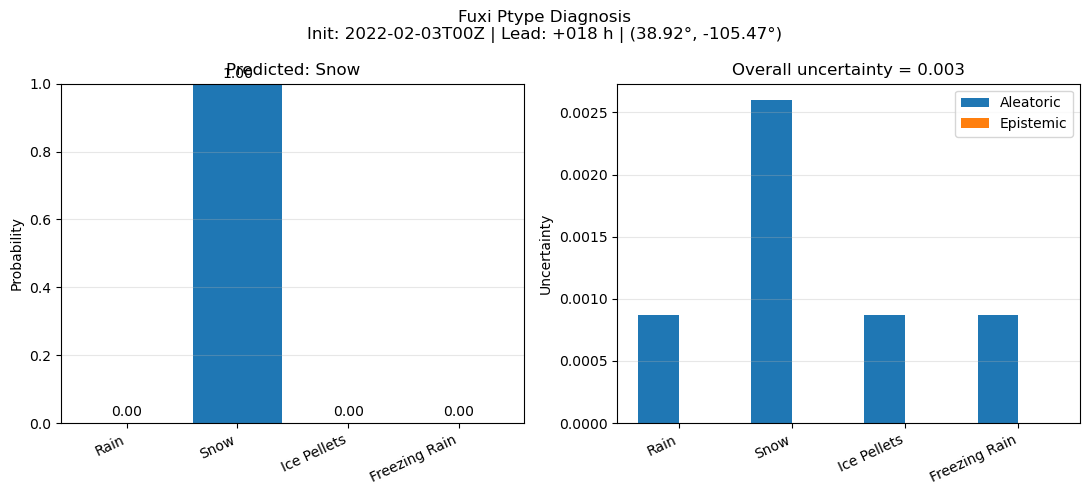

In [5]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# Open one forecast file
# ------------------------------------------------------------
path = (
   '/glade/derecho/scratch/sakor/bulk/era5_init/ML_PTYPE/fuxi_ptype/2022-02-03T00Z/fuxi_2022-02-03T00Z_018.nc'
)

ds = xr.open_dataset(path)


# ------------------------------------------------------------
# Select arbitrary location
# ------------------------------------------------------------
target_lat = 39.0
target_lon = -105.5

point = ds.sel(latitude=target_lat, longitude=target_lon, method="nearest").isel(time=0)

selected_lat = float(point.latitude.values)
selected_lon = float(point.longitude.values)

print(f"Requested point : ({target_lat:.2f}, {target_lon:.2f})")
print(f"Selected point  : ({selected_lat:.2f}, {selected_lon:.2f})")


# ------------------------------------------------------------
# Ptype information
# ------------------------------------------------------------
ptype_names = ["Rain", "Snow", "Ice Pellets", "Freezing Rain"]
ptype_vars = ["ML_rain", "ML_snow", "ML_icep", "ML_frzr"]
ptype_short = ["rain", "snow", "icep", "frzr"]

probabilities = np.array([float(point[var].values) for var in ptype_vars])

if "ML_ptype" in point:
    predicted_index = int(point["ML_ptype"].values)
else:
    predicted_index = int(np.argmax(probabilities))

predicted_ptype = ptype_names[predicted_index]
predicted_probability = probabilities[predicted_index]


# ------------------------------------------------------------
# Overall evidential uncertainty
# ------------------------------------------------------------
overall_uncertainty = float(point["ML_u"].values) if "ML_u" in point else np.nan


# ------------------------------------------------------------
# Class-specific aleatoric / epistemic uncertainty
# ------------------------------------------------------------
aleatoric = np.array([
    float(point[f"ML_{name}_ale"].values) if f"ML_{name}_ale" in point else np.nan
    for name in ptype_short
])

epistemic = np.array([
    float(point[f"ML_{name}_epi"].values) if f"ML_{name}_epi" in point else np.nan
    for name in ptype_short
])


# ------------------------------------------------------------
# Forecast metadata
# ------------------------------------------------------------
model = ds.attrs.get("model", "unknown")
init = ds.attrs.get("initialization_time", "unknown")
lead = ds.attrs.get("forecast_lead_hours", "unknown")


# ------------------------------------------------------------
# Print diagnosis
# ------------------------------------------------------------
print("\n" + "=" * 60)
print("PRECIPITATION-TYPE DIAGNOSIS")
print("=" * 60)

print(f"Model          : {model}")
print(f"Initialization : {init}")
print(f"Forecast lead  : +{int(lead):03d} h")
print(f"Location       : ({selected_lat:.2f}, {selected_lon:.2f})")

print("\nClass probabilities:")
for name, prob in zip(ptype_names, probabilities):
    print(f"  {name:<16s}: {prob:.4f}")

print(f"\nPredicted ptype : {predicted_ptype}")
print(f"Probability     : {predicted_probability:.4f}")

if np.isfinite(overall_uncertainty):
    print(f"Overall uncertainty : {overall_uncertainty:.4f}")

print("\nClass-specific uncertainty:")
for name, prob, ale, epi in zip(ptype_names, probabilities, aleatoric, epistemic):
    print(f"  {name:<16s} P={prob:.4f}   ALE={ale:.4f}   EPI={epi:.4f}")

print("=" * 60)


# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------
x = np.arange(len(ptype_names))

fig, axes = plt.subplots(1, 2, figsize=(11, 5))


# Ptype probabilities
axes[0].bar(x, probabilities)
axes[0].set_xticks(x)
axes[0].set_xticklabels(ptype_names, rotation=25, ha="right")
axes[0].set_ylim(0, 1)
axes[0].set_ylabel("Probability")
axes[0].set_title(f"Predicted: {predicted_ptype}")
axes[0].grid(axis="y", alpha=0.3)

for i, prob in enumerate(probabilities):
    axes[0].text(i, prob + 0.02, f"{prob:.2f}", ha="center")


# Aleatoric / epistemic uncertainty
width = 0.36

axes[1].bar(x - width / 2, aleatoric, width=width, label="Aleatoric")
axes[1].bar(x + width / 2, epistemic, width=width, label="Epistemic")

axes[1].set_xticks(x)
axes[1].set_xticklabels(ptype_names, rotation=25, ha="right")
axes[1].set_ylabel("Uncertainty")
axes[1].set_title(f"Overall uncertainty = {overall_uncertainty:.3f}")
axes[1].grid(axis="y", alpha=0.3)
axes[1].legend()


fig.suptitle(
    f"{model.capitalize()} Ptype Diagnosis\n"
    f"Init: {init} | Lead: +{int(lead):03d} h | "
    f"({selected_lat:.2f}°, {selected_lon:.2f}°)"
)

plt.tight_layout()
plt.show()

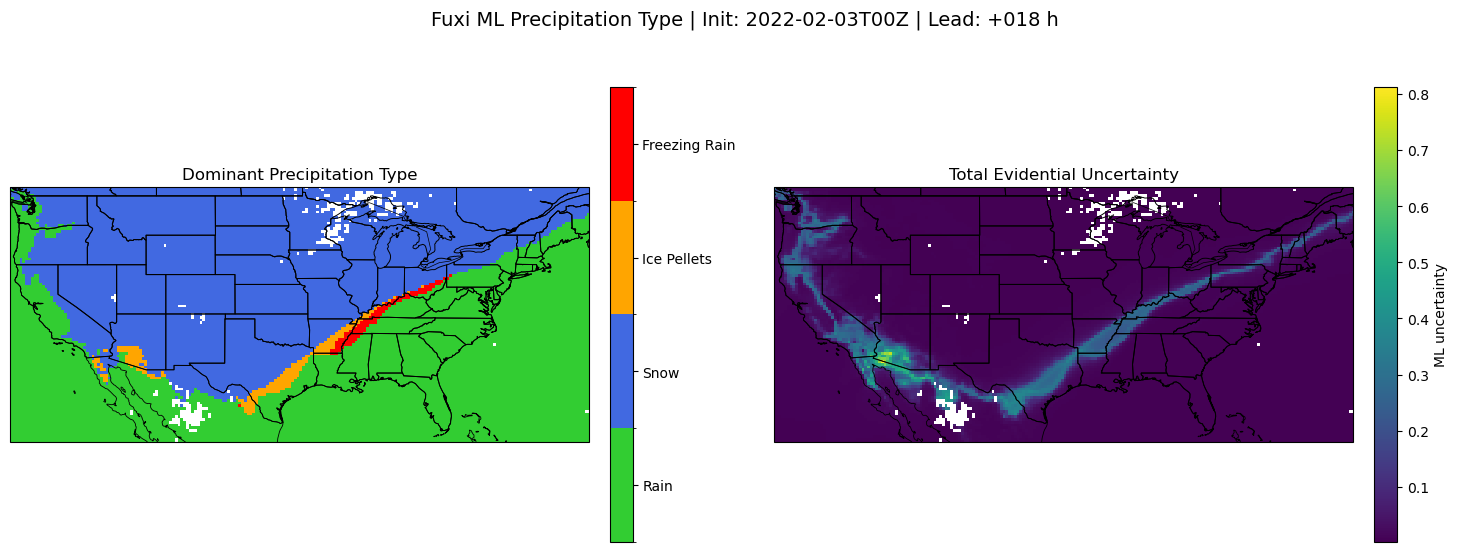

In [6]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
import cartopy.crs as ccrs
import cartopy.feature as cfeature



ds = xr.open_dataset(path, decode_timedelta=True).isel(time=0)


# ------------------------------------------------------------
# Ptype probabilities
# ------------------------------------------------------------
ptype_probs = xr.concat(
    [ds["ML_rain"], ds["ML_snow"], ds["ML_icep"], ds["ML_frzr"]],
    dim="ptype_class",
)

# Valid where at least one class probability is finite
valid = np.isfinite(ptype_probs).any(dim="ptype_class")

# Replace NaNs temporarily so argmax can run
ptype_dom = ptype_probs.fillna(-np.inf).argmax(dim="ptype_class")

# Mask locations where ALL classes were NaN
ptype_dom = ptype_dom.where(valid)


# ------------------------------------------------------------
# Total uncertainty
# ------------------------------------------------------------
uncertainty = ds["ML_u"].where(valid)


# ------------------------------------------------------------
# Coordinates
# ------------------------------------------------------------
lon = ds["longitude"]
lat = ds["latitude"]

extent = [
    float(lon.min()),
    float(lon.max()),
    float(lat.min()),
    float(lat.max()),
]


# ------------------------------------------------------------
# Ptype colors
# ------------------------------------------------------------
ptype_names = ["Rain", "Snow", "Ice Pellets", "Freezing Rain"]

ptype_cmap = ListedColormap([
    "limegreen",
    "royalblue",
    "orange",
    "red",
])

ptype_norm = BoundaryNorm(
    [-0.5, 0.5, 1.5, 2.5, 3.5],
    ptype_cmap.N,
)


# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------
proj = ccrs.PlateCarree()

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 6),
    subplot_kw={"projection": proj},
)


# Dominant ptype
im0 = axes[0].pcolormesh(
    lon, lat, ptype_dom,
    cmap=ptype_cmap,
    norm=ptype_norm,
    shading="auto",
    transform=proj,
)

axes[0].set_extent(extent, crs=proj)
axes[0].add_feature(cfeature.STATES.with_scale("50m"), linewidth=0.7)
axes[0].add_feature(cfeature.BORDERS.with_scale("50m"), linewidth=0.5)
axes[0].coastlines(resolution="50m", linewidth=0.6)
axes[0].set_title("Dominant Precipitation Type")

cbar0 = fig.colorbar(im0, ax=axes[0], shrink=0.85, pad=0.03)
cbar0.set_ticks([0, 1, 2, 3])
cbar0.set_ticklabels(ptype_names)


# Total uncertainty
im1 = axes[1].pcolormesh(
    lon, lat, uncertainty,
    shading="auto",
    transform=proj,
)

axes[1].set_extent(extent, crs=proj)
axes[1].add_feature(cfeature.STATES.with_scale("50m"), linewidth=0.7)
axes[1].add_feature(cfeature.BORDERS.with_scale("50m"), linewidth=0.5)
axes[1].coastlines(resolution="50m", linewidth=0.6)
axes[1].set_title("Total Evidential Uncertainty")

cbar1 = fig.colorbar(im1, ax=axes[1], shrink=0.85, pad=0.03)
cbar1.set_label("ML uncertainty")


# ------------------------------------------------------------
# Title
# ------------------------------------------------------------
model = ds.attrs.get("model", "GraphCast")
init = ds.attrs.get("initialization_time", "unknown")
lead = ds.attrs.get("forecast_lead_hours", "unknown")

fig.suptitle(
    f"{model.capitalize()} ML Precipitation Type | "
    f"Init: {init} | Lead: +{int(lead):03d} h",
    fontsize=14,
)

plt.tight_layout()
plt.show()

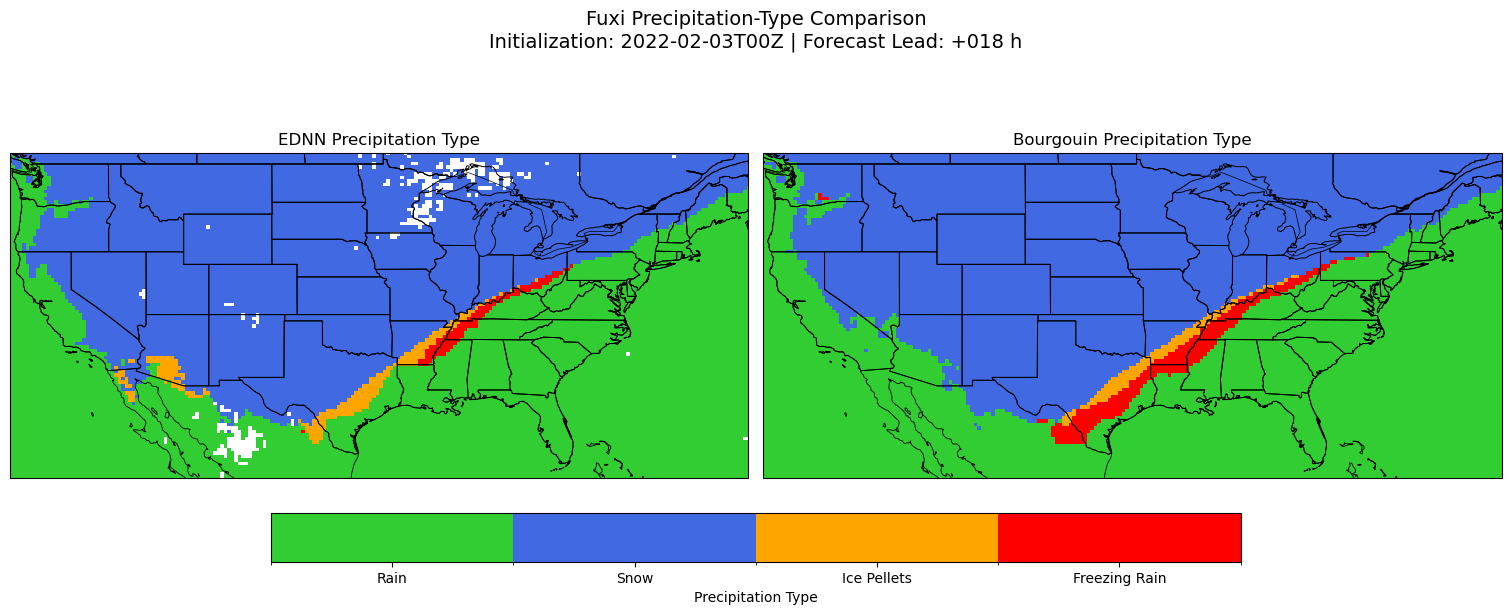

In [7]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
import cartopy.crs as ccrs
import cartopy.feature as cfeature


# ------------------------------------------------------------
# Open one forecast file
# ------------------------------------------------------------

ds = xr.open_dataset(
    path,
    decode_timedelta=True,
).isel(time=0)


# ------------------------------------------------------------
# EDNN precipitation type
#
# Class IDs:
#   0 = rain
#   1 = snow
#   2 = ice pellets
#   3 = freezing rain
#  -1 = invalid
# ------------------------------------------------------------

if "ML_ptype" in ds:

    ednn_ptype = ds["ML_ptype"].where(
        ds["ML_ptype"] >= 0
    )

else:

    # Fallback: calculate the dominant class from probabilities.
    ednn_probabilities = xr.concat(
        [
            ds["ML_rain"],
            ds["ML_snow"],
            ds["ML_icep"],
            ds["ML_frzr"],
        ],
        dim="ptype_class",
    )

    ednn_valid = np.isfinite(
        ednn_probabilities
    ).any(
        dim="ptype_class"
    )

    ednn_ptype = (
        ednn_probabilities
        .fillna(-np.inf)
        .argmax(dim="ptype_class")
        .where(ednn_valid)
    )


# ------------------------------------------------------------
# Bourgouin precipitation type
# ------------------------------------------------------------

if "BOURG_ptype" not in ds:
    raise KeyError(
        "The dataset does not contain 'BOURG_ptype'. "
        "Regenerate this forecast lead with the Bourgouin "
        "classification enabled."
    )

bourgouin_ptype = ds["BOURG_ptype"].where(
    ds["BOURG_ptype"] >= 0
)


# ------------------------------------------------------------
# Coordinates and map extent
# ------------------------------------------------------------

lon = ds["longitude"]
lat = ds["latitude"]

extent = [
    float(lon.min()),
    float(lon.max()),
    float(lat.min()),
    float(lat.max()),
]


# ------------------------------------------------------------
# Shared precipitation-type colors
# ------------------------------------------------------------

ptype_names = [
    "Rain",
    "Snow",
    "Ice Pellets",
    "Freezing Rain",
]

ptype_cmap = ListedColormap(
    [
        "limegreen",
        "royalblue",
        "orange",
        "red",
    ]
)

# Display invalid/NaN locations as transparent.
ptype_cmap.set_bad(
    color=(1.0, 1.0, 1.0, 0.0)
)

ptype_norm = BoundaryNorm(
    [-0.5, 0.5, 1.5, 2.5, 3.5],
    ncolors=ptype_cmap.N,
)


# ------------------------------------------------------------
# Create maps
# ------------------------------------------------------------

projection = ccrs.PlateCarree()

fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(15, 6),
    subplot_kw={"projection": projection},
    constrained_layout=True,
)

fields = [
    ednn_ptype,
    bourgouin_ptype,
]

titles = [
    "EDNN Precipitation Type",
    "Bourgouin Precipitation Type",
]

images = []

for axis, field, title in zip(
    axes,
    fields,
    titles,
):

    image = axis.pcolormesh(
        lon,
        lat,
        field,
        cmap=ptype_cmap,
        norm=ptype_norm,
        shading="auto",
        transform=projection,
    )

    images.append(image)

    axis.set_extent(
        extent,
        crs=projection,
    )

    axis.add_feature(
        cfeature.STATES.with_scale("50m"),
        linewidth=0.7,
    )

    axis.add_feature(
        cfeature.BORDERS.with_scale("50m"),
        linewidth=0.5,
    )

    axis.coastlines(
        resolution="50m",
        linewidth=0.6,
    )

    axis.set_title(
        title,
        fontsize=12,
    )


# ------------------------------------------------------------
# One shared categorical colorbar
# ------------------------------------------------------------

colorbar = fig.colorbar(
    images[0],
    ax=axes,
    orientation="horizontal",
    shrink=0.65,
    pad=0.07,
    ticks=[0, 1, 2, 3],
)

colorbar.ax.set_xticklabels(
    ptype_names
)

colorbar.set_label(
    "Precipitation Type"
)


# ------------------------------------------------------------
# Figure metadata
# ------------------------------------------------------------

model = ds.attrs.get(
    "model",
    "GraphCast",
)

init = ds.attrs.get(
    "initialization_time",
    "unknown",
)

lead = ds.attrs.get(
    "forecast_lead_hours",
    "unknown",
)

try:
    lead_label = f"+{int(lead):03d} h"
except (TypeError, ValueError):
    lead_label = str(lead)


fig.suptitle(
    f"{model.capitalize()} Precipitation-Type Comparison\n"
    f"Initialization: {init} | Forecast Lead: {lead_label}",
    fontsize=14,
)

plt.show()